# PROSPECT M24 — same craft window, station walked home

**One GPU.** Shut down notebook 15 and notebook 16 before Run All. This notebook does not resume M21, M22, or M23.

M22 places the table and furnace beside the ore. This run is that recipe with teacher **v3**: craft as soon as the recipe is in hand, and walk to the home station outside the 9×7 crop. The craft window stays at 0.5. The takeover teacher is v3, not v4. Weights load from `checkpoints/m20_local_map/ckpt_final.pt`. The replay is new. Eval does not use the teacher.

**100k is the stop.** The score on the line is actor-only. `assist_px` is the walk-home teacher. `actor_px` is the policy alone. A low `actor_px` is a possible result of this switch, not a reason to stop. Stop if the opening teacher log shows `iron_pickaxe` 0. Interrupt to save, then restart the kernel and Run All to continue.


In [1]:
from __future__ import annotations

import gc
import json
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
elif not (ROOT / "src").is_dir():
    for candidate in (ROOT, *ROOT.parents):
        if (candidate / "src").is_dir() and (candidate / "configs").is_dir():
            ROOT = candidate
            break
os.chdir(ROOT)
src = str(ROOT / "src")
if src not in sys.path:
    sys.path.insert(0, src)
scripts = str(ROOT / "scripts")
if scripts not in sys.path:
    sys.path.insert(0, scripts)

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import clear_output, display
from torch.utils.tensorboard import SummaryWriter

from training.ckpt import resolve_outer_resume
from training.collect import Collector
from training.crafter_teacher import CrafterTeacherV2, assist_teacher_kwargs
from training.crafter_score import ACHIEVEMENT_NAMES, load_jsonl, score_from_episodes, success_percents
from training.device import (
    configure_runtime,
    describe_device,
    get_device,
    make_grad_scaler,
    parse_amp,
    require_free_vram,
    vram_peak_gb,
    warn_if_not_cuda,
)
from training.evaluate import evaluate_policy, save_eval_gif
from training.imagine import decode_imagination
from training.outer_loop import (
    absorb_finished,
    crossed_interval,
    flush_episode_window,
    joint_payload,
    load_checkpoint,
    loop_updates,
    outer_cycle,
    save_checkpoint,
    save_replay,
)
from training.returns import PercentileReturnNorm
from train_actor_critic import save_imagination_gif, save_imagination_strip
from train_agent import (
    load_replay,
    overlay_wm_train,
    prefill_replay,
    pretrain_dreamer,
    load_seed_actor_critic,
    load_seed_world_model,
    load_yaml,
    log_eval,
    make_actor_critic,
    make_envs,
    make_slow_critic,
    record_finished_episodes,
)
from train_world_model import set_seed

RESUME = "auto"
# Continues checkpoints/m24_walk_home when one exists, including after Interrupt.
# A first start with an empty dir still begins at env step 0.
CONFIG = Path("configs/m24_walk_home.yaml")
ONE_DAY_ENV = 50_000
HALF_ENV = 100_000
cfg = load_yaml(CONFIG)
train = cfg["train"]
if RESUME not in (None, "auto", "latest"):
    raise RuntimeError(f"M24 allows RESUME=None or \"auto\", got {RESUME!r}")
for _key in ("world_model_ckpt", "actor_critic_ckpt"):
    _path = Path(str(cfg.get(_key) or ""))
    if "m20_local_map" not in str(_path).replace("\\", "/") or not _path.is_file():
        raise RuntimeError(
            f"M24 needs {_key} to be the M20 final checkpoint, got {cfg.get(_key)!r}."
        )
if bool(cfg.get("reset_actor", True)):
    raise RuntimeError("M24 loads the M20 actor. reset_actor must be false.")
if int(train.get("teacher_version", 0) or 0) != 3:
    raise RuntimeError(f"M24 teacher_version must be 3, got {train.get('teacher_version')!r}.")
if float(train.get("craft_window_fraction", -1)) != 0.5:
    raise RuntimeError(
        f"M24 craft_window_fraction must be 0.5, got {train.get('craft_window_fraction')!r}."
    )
if int(train.get("env_steps", 0) or 0) != 100_000:
    raise RuntimeError(f"M24 stop is 100k, got env_steps={train.get('env_steps')!r}.")
_ckpt = str(train["checkpoint_dir"]).replace("\\", "/")
if "m24_walk_home" not in _ckpt or any(
    tag in _ckpt
    for tag in (
        "m8_xl_acfix", "m7_xl", "m7_paper", "m9_xl", "m10_xl_r128",
        "m11_xl", "m12_xl", "m13_xl", "m14_xl", "m15_xl", "m16_xl", "m17_xl", "m18_masked", "m19_facing", "m20_local_map", "m21_iron_craft", "m22_field_craft", "m23_uniform_window",
    )
):
    raise RuntimeError(
        f"refusing checkpoint_dir={train['checkpoint_dir']}: M24 writes "
        "checkpoints/m24_walk_home. Restart the kernel."
    )
_wm_check, _ac_check = loop_updates(train)
if (
    float(train.get("train_ratio") or 0) != 512
    or int(train["seq_len"]) != 64
    or int(train["batch_size"]) != 8
    or int(train.get("replay_max_steps", 0) or 0) != 1000000
    or int(train.get("ac_warmup_env", 0) or 0) != 0
    or int(train.get("prefill_steps", 0) or 0) != 2500
    or not bool(train.get("prefill_mask_illegal", False))
    or _wm_check != 16
    or _ac_check != 16
):
    raise RuntimeError(
        f"refusing {CONFIG.name} ratio={train.get('train_ratio')} "
        f"seq={train.get('seq_len')} batch={train.get('batch_size')} "
        f"updates={_wm_check}/{_ac_check} warmup={train.get('ac_warmup_env')} "
        f"prefill={train.get('prefill_steps')} mask_illegal={train.get('prefill_mask_illegal')}. "
        "Need 512, seq 64, batch 8, replay 1e6, warmup 0, prefill 2500, mask_illegal True."
    )
set_seed(int(cfg["seed"]))
device = get_device()
configure_runtime(device)
print(
    f"cudnn benchmark {torch.backends.cudnn.benchmark} "
    "(off on purpose: autotune locked the last run at 0.41 env/s)",
    flush=True,
)
warn_if_not_cuda(device)
print(
    f"vram free {require_free_vram(device):.2f} GiB before the weights load. "
    "One XL trainer fills this card.",
    flush=True,
)
print(f"device: {describe_device(device)}")
_wm_u, _ac_u = loop_updates(train)
print(
    f"amp={train.get('amp', 'bf16')} batch={train['batch_size']} seq={train['seq_len']} "
    f"collect_every={train['collect_every']} env_steps={train['env_steps']} "
    f"cap={train['max_episode_steps']} start_mode={train.get('start_mode', 'all')}"
)
print(
    f"config={CONFIG.name}  ckpt={train['checkpoint_dir']}  "
    f"train_ratio={train.get('train_ratio')}  wm/ac_updates={_wm_u}/{_ac_u}  "
    f"ac_warmup_env={int(train.get('ac_warmup_env', 0) or 0)}  "
    f"prefill={int(train.get('prefill_steps', 0) or 0)}  "
    f"prefill_mask_illegal={bool(train.get('prefill_mask_illegal', False))}  "
    f"inventory_scale={train.get('inventory_scale')}  "
    f"spatial_scale={train.get('spatial_scale')}  RESUME={RESUME!r}"
)
print("DEVIATION: M22 recipe, teacher v3 walks the station home. Craft window stays 0.5.")


cudnn benchmark False (off on purpose: autotune locked the last run at 0.41 env/s)
vram free 14.63 GiB before the weights load. One XL trainer fills this card.
device: cuda  NVIDIA GeForce RTX 5080  15.9 GiB  cc12.0  torch 2.11.0+cu128
amp=bf16 batch=8 seq=64 collect_every=16 env_steps=100000 cap=10000 start_mode=all
config=m24_walk_home.yaml  ckpt=checkpoints/m24_walk_home  train_ratio=512  wm/ac_updates=16/16  ac_warmup_env=0  prefill=2500  prefill_mask_illegal=True  inventory_scale=1.0  spatial_scale=1.0  RESUME='auto'
DEVIATION: M22 recipe, teacher v3 walks the station home. Craft window stays 0.5.


In [2]:
world_model, wm_cfg = load_seed_world_model(cfg, device)
if (
    world_model.inventory_head is None
    or world_model.spatial_head is None
    or world_model.local_map_head is None
):
    raise RuntimeError(
        "world_model has no inventory_head, spatial_head, or local_map_head — configs/sizes/dreamer_xl_paper_local.yaml "
        "did not load. Check world_model_config in configs/m24_walk_home.yaml."
    )
wm_train_cfg = overlay_wm_train(dict(wm_cfg["train"]), train)
actor, critic = make_actor_critic(cfg, world_model, device)
print(
    f"actor/critic feat_dim={actor.feat_dim if hasattr(actor, 'feat_dim') else 'n/a'}  "
    f"inventory_head.n_items={world_model.inventory_head.n_items}  spatial_head.n_materials={world_model.spatial_head.n_materials}  local_map_cells={world_model.local_map_head.cells}"
)
wm_optim = torch.optim.Adam(world_model.parameters(), lr=float(train["wm_lr"]))
ac_optim = torch.optim.Adam(
    [
        {"params": actor.parameters(), "lr": float(train["actor_lr"])},
        {"params": critic.parameters(), "lr": float(train["critic_lr"])},
    ]
)
retnorm = PercentileReturnNorm()
slow_critic = (
    make_slow_critic(cfg, critic, device)
    if bool(cfg.get("critic", {}).get("slow_target", True))
    else None
)
amp_dtype = parse_amp(train.get("amp", "bf16"), device)
scaler = make_grad_scaler(device, amp_dtype)

ckpt_dir = Path(train["checkpoint_dir"])
results_dir = Path(train["results_dir"])
log_dir = Path(train["log_dir"])
replay_out = Path(train["replay_out"])
for p in (ckpt_dir, results_dir, log_dir, replay_out.parent):
    p.mkdir(parents=True, exist_ok=True)

resume_path = resolve_outer_resume(RESUME, ckpt_dir, seed_joint=cfg.get("seed_joint_ckpt"))
env_steps = 0
wm_steps = 0
ac_steps = 0
collect_seed = int(cfg["seed"])
if resume_path is not None:
    _resume = str(resume_path).replace("\\", "/")
    if "m24_walk_home" not in _resume:
        raise RuntimeError(
            f"refusing {resume_path}: M24 only continues checkpoints/m24_walk_home."
        )
    if RESUME is None:
        raise RuntimeError(
            f"found {resume_path} but RESUME=None. Delete it for a fresh start, "
            "or set RESUME=\"auto\" to continue this run."
        )
    counters = load_checkpoint(
        resume_path, world_model, wm_optim, actor, critic, ac_optim,
        retnorm, device, slow_critic=slow_critic,
    )
    env_steps = counters["env_steps"]
    wm_steps = counters["wm_steps"]
    ac_steps = counters["ac_steps"]
    collect_seed = counters["collect_seed"]
    print(f"continuing THIS M24 run {resume_path} at env_steps={env_steps}")
elif not bool(cfg.get("reset_actor", False)) and cfg.get("actor_critic_ckpt"):
    load_seed_actor_critic(cfg, actor, critic, ac_optim, retnorm, device, slow_critic=slow_critic)
else:
    print("actor-critic random init (reset_actor)")
    raise RuntimeError("M24 must load the M20 actor. reset_actor is false and actor_critic_ckpt is required.")

buffer = load_replay(cfg, train, resume=resume_path is not None)
collect_env, eval_env = make_envs(cfg)
craft_assist_prob = float(train.get("craft_assist", 0.0) or 0.0)
_teacher_version = int(train.get("teacher_version", 0) or 0)
_teacher_flags = assist_teacher_kwargs(_teacher_version)
craft_teacher = None
if craft_assist_prob > 0.0:
    craft_teacher = CrafterTeacherV2(
        seed=int(cfg["seed"]), **_teacher_flags
    )
print(
    f"craft assist {craft_assist_prob:.2f}: teacher v{_teacher_version} "
    f"field_craft={_teacher_flags['field_craft']} "
    f"craft_window_fraction={float(train.get('craft_window_fraction', -1))}. "
    "After a stone pickaxe the teacher plays through the iron pickaxe, then the life ends. "
    f"survival_assist={bool(train.get('survival_assist', False))}. "
    "assist_px is the teacher. actor_px is the policy alone.",
    flush=True,
)
collector = Collector(
    collect_env,
    world_model,
    actor,
    buffer,
    device=device,
    max_episode_steps=int(train["max_episode_steps"]),
    amp_dtype=amp_dtype,
    seed=collect_seed,
    craft_teacher=craft_teacher,
    craft_assist_prob=craft_assist_prob,
    survival_assist=bool(train.get("survival_assist", False)),
    assist_tail_steps=int(train.get("assist_tail_steps", 32) or 0),
    assist_idle_stop=int(train.get("assist_idle_stop", 200) or 0),
)
if resume_path is None:
    prefill_replay(
        collector,
        buffer,
        seq_len=int(train["seq_len"]),
        steps=int(train.get("prefill_steps", 10000)),
        mask_illegal=bool(train.get("prefill_mask_illegal", False)),
    )
if env_steps == 0 and int(train.get("teacher_episodes", 0) or 0) > 0:
    from training.crafter_teacher import seed_teacher_episodes
    teacher_stats = seed_teacher_episodes(
        collect_env,
        buffer,
        episodes=int(train["teacher_episodes"]),
        max_episode_steps=int(train.get("teacher_max_steps", 800)),
        seed=int(cfg["seed"]) + 10_000,
        version=int(train.get("teacher_version", 2) or 2),
    )
    iron_px = int(teacher_stats["unlocks"].get("make_iron_pickaxe", 0))
    _tv = int(train.get("teacher_version", 2) or 2)
    print(
        f"teacher v{_tv} stone={teacher_stats['stone']}/{teacher_stats['episodes']} "
        f"wood_pickaxe={teacher_stats['pickaxe']} iron_pickaxe={iron_px} "
        f"steps={teacher_stats['steps']} (not the Crafter score; eval stays the actor)"
    )
    if iron_px < 1:
        raise RuntimeError(
            f"teacher v{_tv} iron pickaxe {iron_px}/{teacher_stats['episodes']}. "
            "Refusing to train on lives that never craft it."
        )
    if teacher_stats["stone"] < teacher_stats["episodes"] // 2:
        raise RuntimeError(
            f"teacher stone {teacher_stats['stone']}/{teacher_stats['episodes']} "
            "is below half. Refusing to train a world model that still has no mining."
        )
if env_steps == 0:
    pre_wm, pre_ac = pretrain_dreamer(
        world_model,
        wm_optim,
        actor,
        critic,
        ac_optim,
        buffer,
        device=device,
        wm_train_cfg=wm_train_cfg,
        train=train,
        retnorm=retnorm,
        slow_critic=slow_critic,
        amp_dtype=amp_dtype,
        scaler=scaler,
    )
    wm_steps += pre_wm
    ac_steps += pre_ac
n_m = sum(p.numel() for p in world_model.parameters()) / 1e6
print(f"replay episodes={len(buffer)} steps={buffer.num_steps}  wm={n_m:.1f}M params")


world model from joint checkpoints\m20_local_map\ckpt_final.pt (env_steps 200000)
actor/critic feat_dim=6484  inventory_head.n_items=16  spatial_head.n_materials=12  local_map_cells=63
continuing THIS M24 run checkpoints\m24_walk_home\ckpt_latest.pt at env_steps=48512
replay resumed data\m24_walk_home_replay.pt: episodes=269 steps=62993
craft assist 1.00: teacher v3 field_craft=False craft_window_fraction=0.5. After a stone pickaxe the teacher plays through the iron pickaxe, then the life ends. survival_assist=False. assist_px is the teacher. actor_px is the policy alone.
replay episodes=269 steps=62993  wm=257.3M params


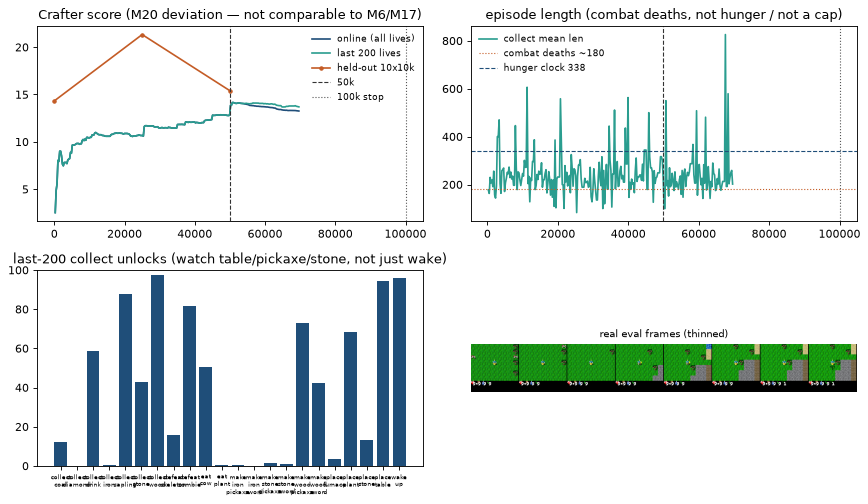

done checkpoints\m24_walk_home\ckpt_final.pt


KeyboardInterrupt: 

: 

In [ ]:
# Leftover kernel from a different notebook still has the old collector in memory.
_old = str(ckpt_dir).replace("\\", "/") + " " + str(results_dir).replace("\\", "/")
if any(
    tag in _old
    for tag in ("m11", "m12_xl", "m13_xl", "m14_xl", "m15_xl", "m16_xl", "m17_xl", "m18_masked", "m19_facing", "m22_field_craft", "m23_uniform_window")
):
    raise RuntimeError(
        f"this kernel is still on {ckpt_dir} / {results_dir}. "
        "Interrupt, restart the kernel, then run EVERY cell from the top. "
        "Do not re-run only this cell. Leave a live M17 kernel alone."
    )

# Hard re-bind. A leftover kernel from another notebook must die here.
CONFIG = Path("configs/m24_walk_home.yaml")
cfg = load_yaml(CONFIG)
train = cfg["train"]
ckpt_dir = Path(train["checkpoint_dir"])
results_dir = Path(train["results_dir"])
log_dir = Path(train["log_dir"])
replay_out = Path(train["replay_out"])
for _p in (ckpt_dir, results_dir, log_dir, replay_out.parent):
    _p.mkdir(parents=True, exist_ok=True)
ONE_DAY_ENV = 50_000
HALF_ENV = 100_000
_wm_u, _ac_u = loop_updates(train)
if (
    CONFIG.name != "m24_walk_home.yaml"
    or float(train.get("train_ratio") or 0) != 512
    or int(train["seq_len"]) != 64
    or int(train["batch_size"]) != 8
    or _wm_u != 16
    or _ac_u != 16
    or int(train.get("ac_warmup_env", 0) or 0) != 0
    or int(train.get("teacher_version", 0) or 0) != 3
    or float(train.get("craft_window_fraction", -1)) != 0.5
    or int(train.get("env_steps", 0) or 0) != 100_000
    or not bool(train.get("prefill_mask_illegal", False))
    or "m24_walk_home" not in str(ckpt_dir).replace("\\", "/")
):
    raise RuntimeError(
        f"refusing {CONFIG.name} ratio={train.get('train_ratio')} "
        f"seq={train.get('seq_len')} batch={train.get('batch_size')} "
        f"wm/ac={_wm_u}/{_ac_u} ckpt={ckpt_dir}. Restart kernel, run ALL cells."
    )
if (
    world_model.inventory_head is None
    or world_model.spatial_head is None
    or world_model.local_map_head is None
):
    raise RuntimeError("world_model lost its inventory_head, spatial_head, or local_map_head — restart the kernel, run ALL cells.")

writer = SummaryWriter(log_dir=str(log_dir))
history: list[dict] = []
eval_history: list[dict] = []
metrics_path = results_dir / "train_metrics.json"
eval_path = results_dir / "eval_metrics.json"
episodes_path = results_dir / "collect_episodes.jsonl"
collect_log = load_jsonl(episodes_path)
if env_steps > 0 and metrics_path.is_file():
    prev = json.loads(metrics_path.read_text(encoding="utf-8"))
    history = [h for h in prev if int(h.get("env_steps", 0)) <= env_steps]
if env_steps > 0 and eval_path.is_file():
    prev_e = json.loads(eval_path.read_text(encoding="utf-8"))
    eval_history = [h for h in prev_e if int(h.get("env_steps", 0)) <= env_steps]
if env_steps > 0:
    collect_log = [r for r in collect_log if int(r.get("env_steps", 0)) <= env_steps]
else:
    collect_log = []

target = int(train["env_steps"])
collect_every = int(train["collect_every"])
from training.outer_loop import loop_updates

wm_updates, ac_updates = loop_updates(train, env_steps=env_steps)
imag_gradient = str(train.get("imag_gradient", "reinforce"))
eval_every = int(train["eval_every"])
log_every = int(train["log_every"])
dashboard_every = int(train.get("dashboard_every", 1000))
image_every = int(train["image_every"])
ckpt_every = int(train["checkpoint_every"])
replay_every = int(train.get("replay_every", ckpt_every))
start_mode = str(train.get("start_mode", "all"))
last_vis = None
last_eval_frames = None
last_percents: dict[str, float] = {}


def _actor_rows(rows: list[dict]) -> list[dict]:
    return [r for r in rows if not int(r.get("assisted", 0))]


def _iron_pickaxe_count(rows: list[dict]) -> int:
    return sum(1 for r in rows if int(r.get("achievement_make_iron_pickaxe", 0)) >= 1)


def refresh_last200_percents() -> None:
    """Bar chart is the actor's last-200, not assisted lives and not the n=10 eval."""
    global last_percents
    rows = _actor_rows(collect_log)
    if rows:
        last_percents = success_percents(rows[-200:])
    else:
        last_percents = {n: 0.0 for n in ACHIEVEMENT_NAMES}


refresh_last200_percents()

_ckpt = str(ckpt_dir).replace("\\", "/")
if "m24_walk_home" not in _ckpt or any(
    tag in _ckpt
    for tag in (
        "m8_xl_acfix", "m7_xl", "m7_paper", "m9_xl", "m10_xl_r128",
        "m11_xl", "m12_xl", "m13_xl", "m14_xl", "m15_xl", "m16_xl", "m17_xl", "m18_masked", "m19_facing", "m20_local_map", "m21_iron_craft", "m22_field_craft", "m23_uniform_window",
    )
):
    raise RuntimeError(
        f"this kernel is still writing {ckpt_dir} at env_steps={env_steps}. "
        "Shut down every other trainer first. This notebook writes "
        "checkpoints/m24_walk_home."
    )


def _thin_history(hist: list[dict], max_points: int = 800) -> list[dict]:
    if len(hist) <= max_points:
        return hist
    stride = max(1, len(hist) // max_points)
    return hist[::stride]


def _dashboard_strip(images: np.ndarray, keep_every: int = 2) -> np.ndarray:
    tiles = [images[i] for i in range(0, images.shape[0], keep_every)]
    return np.concatenate(tiles, axis=1)


def show_progress(hist, evals, vis_nchw, eval_frames, percents, steps_per_sec=None):
    status = ""
    if hist:
        h = hist[-1]
        rate = f"  ({steps_per_sec:.2f} env/s)" if steps_per_sec else ""
        ev = evals[-1].get("eval_crafter_score", float("nan")) if evals else float("nan")
        ep_len = float("nan")
        for p in reversed(hist):
            if "collect_ep_len" in p and np.isfinite(p.get("collect_ep_len", float("nan"))):
                ep_len = float(p["collect_ep_len"])
                break
        ev_len = evals[-1].get("eval_length", float("nan")) if evals else float("nan")
        status = (
            f"env {h['env_steps']}/{target}  heldout_score={ev:.3f}  "
            f"online_score={h.get('online_crafter_score', float('nan')):.3f}  "
            f"last200={h.get('online_crafter_score_last200', float('nan')):.3f}  "
            f"ac_H={h.get('ac_entropy', float('nan')):.3f}  "
            f"ep_len={ep_len:.0f}  eval_len={ev_len:.0f}  "
            f"actor_px={int(h.get('actor_iron_pickaxe', 0))}  "
            f"assist_px={int(h.get('assist_iron_pickaxe', 0))}/{int(h.get('assist_lives', 0))}{rate}"
        )
    if status:
        print(status, flush=True)
    fig = None
    try:
        clear_output(wait=True)
        plot_h = _thin_history(hist)
        fig = plt.figure(figsize=(11, 6.4), dpi=80)
        ax0 = fig.add_subplot(2, 2, 1)
        if plot_h:
            ax0.plot(
                [p["env_steps"] for p in plot_h],
                [p.get("online_crafter_score", float("nan")) for p in plot_h],
                color="#1f4e79",
                label="online (all lives)",
            )
            ax0.plot(
                [p["env_steps"] for p in plot_h],
                [p.get("online_crafter_score_last200", float("nan")) for p in plot_h],
                color="#2a9d8f",
                label="last 200 lives",
            )
        if evals:
            ax0.plot(
                [p["env_steps"] for p in evals],
                [p.get("eval_crafter_score", float("nan")) for p in evals],
                color="#c45c26",
                marker=".",
                label="held-out 10x10k",
            )
        ax0.axvline(ONE_DAY_ENV, color="#333", ls="--", lw=1, label="50k")
        ax0.axvline(HALF_ENV, color="#555", ls=":", lw=1, label="100k stop")
        ax0.set_title("Crafter score (M20 deviation — not comparable to M6/M17)")
        ax0.legend(frameon=False, fontsize=8)
        ax1 = fig.add_subplot(2, 2, 2)
        if plot_h:
            xs = [p["env_steps"] for p in plot_h]
            last_len = float("nan")
            lens = []
            for p in plot_h:
                if "collect_ep_len" in p and np.isfinite(p.get("collect_ep_len", float("nan"))):
                    last_len = float(p["collect_ep_len"])
                lens.append(last_len)
            ax1.plot(xs, lens, color="#2a9d8f", label="collect mean len")
        ax1.axhline(180, color="#c45c26", ls=":", lw=1, label="combat deaths ~180")
        ax1.axhline(338, color="#1f4e79", ls="--", lw=1, label="hunger clock 338")
        ax1.axvline(ONE_DAY_ENV, color="#333", ls="--", lw=1)
        ax1.axvline(HALF_ENV, color="#555", ls=":", lw=1)
        ax1.set_title("episode length (combat deaths, not hunger / not a cap)")
        ax1.legend(frameon=False, fontsize=8)
        ax2 = fig.add_subplot(2, 2, 3)
        if percents:
            names = [n.replace("_", "\n") for n in ACHIEVEMENT_NAMES]
            vals = [percents.get(n, 0.0) for n in ACHIEVEMENT_NAMES]
            ax2.bar(range(len(names)), vals, color="#1f4e79")
            ax2.set_xticks(range(len(names)))
            ax2.set_xticklabels(names, fontsize=5)
        ax2.set_ylim(0, 100)
        ax2.set_title("last-200 collect unlocks (watch table/pickaxe/stone, not just wake)")
        ax3 = fig.add_subplot(2, 2, 4)
        shown = False
        if eval_frames is not None:
            ax3.imshow(_dashboard_strip(eval_frames[:16]))
            ax3.set_title("real eval frames (thinned)", fontsize=9)
            shown = True
        elif vis_nchw is not None:
            seq = vis_nchw[0].detach().float().clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
            ax3.imshow(_dashboard_strip((seq * 255).astype(np.uint8)))
            ax3.set_title("imagined decode (not skill)", fontsize=9)
            shown = True
        if shown:
            ax3.axis("off")
        fig.tight_layout()
        display(fig)
    except Exception as exc:
        print(f"[dashboard skipped: {type(exc).__name__}: {exc}]", flush=True)
    finally:
        if fig is not None:
            plt.close(fig)


def run_eval(step: int):
    global last_eval_frames
    result = evaluate_policy(
        eval_env,
        world_model,
        actor,
        device=device,
        n_episodes=int(train["eval_episodes"]),
        max_steps=int(train.get("eval_max_steps", train["max_episode_steps"])),
        amp_dtype=amp_dtype,
        seed=int(train.get("eval_seed", 100_000)),
    )
    log_eval(result, step, eval_history, writer)
    last_eval_frames = result.frames
    if result.frames is not None:
        save_eval_gif(result.frames, results_dir / f"eval_step_{step:06d}.gif")
    eval_path.write_text(json.dumps(eval_history), encoding="utf-8")


print(
    f"{CONFIG.stem} to {target} env steps on {device} "
    f"(start={env_steps}, remaining={target - env_steps}, "
    f"wm/ac={wm_updates}/{ac_updates}, "
    f"ac_warmup_env={int(train.get('ac_warmup_env', 0) or 0)}, "
    f"imag_gradient={imag_gradient}, "
    f"slow_critic={slow_critic is not None})...",
    flush=True,
)
print("DEVIATION run: 9x7 local map + teacher v2 + BC (findings 47-48). Not 14.5.", flush=True)
print("kill switch: ac_H under 0.10 at 30k means something broke", flush=True)
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

last_log_time = time.time()
last_log_env = env_steps
pending_lens: list[float] = []
pending_rets: list[float] = []
last_ep_len = float("nan")
last_ep_ret = float("nan")
if env_steps == 0 or not eval_history:
    print("held-out 10x10k of the current (fresh) actor...", flush=True)
    t_eval = time.time()
    run_eval(env_steps)
    print(
        f"held-out eval done in {time.time() - t_eval:.0f}s (not counted in env/s)",
        flush=True,
    )
show_progress(history, eval_history, last_vis, last_eval_frames, last_percents)
last_log_time = time.time()
last_log_env = env_steps

try:
    while env_steps < target:
        wm_updates, ac_updates = loop_updates(train, env_steps=env_steps)
        t_cycle = time.time()
        cycle = outer_cycle(
            collector,
            world_model,
            actor,
            critic,
            wm_optim,
            ac_optim,
            buffer,
            device=device,
            wm_train_cfg=wm_train_cfg,
            collect_every=collect_every,
            wm_updates=wm_updates,
            ac_updates=ac_updates,
            batch_size=int(train["batch_size"]),
            seq_len=int(train["seq_len"]),
            retnorm=retnorm,
            horizon=int(train["horizon"]),
            start_mode=start_mode,
            lam=float(train.get("lam", 0.95)),
            discount=float(train.get("discount", 0.997)),
            entropy_scale=float(train.get("entropy_scale", 3.0e-4)),
            imag_gradient=imag_gradient,
            imag_gradient_mix=float(train.get("imag_gradient_mix", 0.0)),
            slow_critic=slow_critic,
            amp_dtype=amp_dtype,
            scaler=scaler,
            wm_max_grad_norm=float(train.get("wm_max_grad_norm", 1000.0)),
            ac_max_grad_norm=float(train.get("ac_max_grad_norm", 100.0)),
            teacher_fraction=float(train.get("teacher_fraction", 0.0) or 0.0),
            craft_window_fraction=float(train.get("craft_window_fraction", 0.5) or 0.0),
            bc_scale=float(train.get("bc_scale", 0.0) or 0.0),
        )
        prev_steps = env_steps
        env_steps += collect_every
        if prev_steps == 0:
            dt_cycle = max(time.time() - t_cycle, 1e-6)
            print(
                f"first cycle {dt_cycle:.1f}s for {collect_every} env steps "
                f"({collect_every / dt_cycle:.2f} env/s). M20's opening rate was ~1.16.",
                flush=True,
            )
        if cycle.wm_metrics is not None:
            wm_steps += wm_updates
        if cycle.ac_metrics is not None:
            ac_steps += ac_updates
        inject_every = int(train.get('teacher_inject_every', 0) or 0)
        inject_n = int(train.get('teacher_inject_episodes', 0) or 0)
        if inject_every > 0 and inject_n > 0 and crossed_interval(prev_steps, env_steps, inject_every):
            from training.crafter_teacher import seed_teacher_episodes
            inj = seed_teacher_episodes(
                collect_env,
                buffer,
                episodes=inject_n,
                max_episode_steps=int(train.get('teacher_max_steps', 800)),
                seed=int(cfg['seed']) + 20_000 + env_steps,
                version=int(train.get('teacher_version', 2) or 2),
            )
            print(
                f"teacher inject env={env_steps} stone={inj['stone']}/{inj['episodes']} "
                f"iron={inj.get('unlocks', {}).get('collect_iron', 0)} "
                f"iron_pickaxe={inj.get('unlocks', {}).get('make_iron_pickaxe', 0)} "
                f"steps={inj['steps']}",
                flush=True,
            )

        row = {"env_steps": env_steps, "wm_steps": wm_steps, "ac_steps": ac_steps}
        if cycle.wm_metrics:
            row.update({f"wm_{k}": v for k, v in cycle.wm_metrics.items()})
        if cycle.ac_metrics:
            row.update({f"ac_{k}": v for k, v in cycle.ac_metrics.items()})
        row["collect_reward"] = float(cycle.collect["reward_mean"])
        row["collect_entropy"] = float(cycle.collect["entropy"])
        finished = cycle.collect.get("episodes") or []
        if finished:
            absorb_finished(finished, pending_lens, pending_rets)
            collect_log = record_finished_episodes(
                finished, env_steps, episodes_path, collect_log
            )
            refresh_last200_percents()

        sps = None
        do_log = (
            crossed_interval(prev_steps, env_steps, log_every)
            or env_steps >= target
        )
        do_dash = crossed_interval(prev_steps, env_steps, dashboard_every)
        if do_log:
            now = time.time()
            dt = max(now - last_log_time, 1e-6)
            sps = (env_steps - last_log_env) / dt
            last_log_time = now
            last_log_env = env_steps
            last_ep_len, last_ep_ret = flush_episode_window(
                pending_lens, pending_rets, last_ep_len, last_ep_ret
            )
            if np.isfinite(last_ep_len):
                row["collect_ep_len"] = last_ep_len
                row["collect_ep_return"] = last_ep_ret
            row["env_steps_per_sec"] = sps
            actor_rows = _actor_rows(collect_log)
            assist_rows = [r for r in collect_log if int(r.get("assisted", 0))]
            if actor_rows:
                online_score, _ = score_from_episodes(actor_rows, budget=target)
                row["online_crafter_score"] = online_score
                recent, _ = score_from_episodes(actor_rows[-200:])
                row["online_crafter_score_last200"] = recent
            row["actor_iron_pickaxe"] = _iron_pickaxe_count(actor_rows[-200:])
            row["assist_iron_pickaxe"] = _iron_pickaxe_count(assist_rows)
            row["assist_lives"] = len(assist_rows)
            history.append(row)
            for k, v in row.items():
                if k != "env_steps" and isinstance(v, (int, float)) and np.isfinite(v):
                    writer.add_scalar(f"loop/{k}", float(v), env_steps)
            vram = vram_peak_gb()
            if vram:
                row["vram_alloc"] = vram[0]
            metrics_path.write_text(json.dumps(history), encoding="utf-8")
            ev = eval_history[-1].get("eval_crafter_score", float("nan")) if eval_history else float("nan")
            print(
                f"env {env_steps}/{target}  heldout_score={ev:.3f}  "
                f"online_score={row.get('online_crafter_score', float('nan')):.3f}  "
                f"last200={row.get('online_crafter_score_last200', float('nan')):.3f}  "
                f"ac_H={row.get('ac_entropy', float('nan')):.3f}  "
                f"ep_len={row.get('collect_ep_len', float('nan')):.0f}  "
                f"actor_px={int(row.get('actor_iron_pickaxe', 0))}/{len(actor_rows[-200:])}  "
                f"assist_px={int(row.get('assist_iron_pickaxe', 0))}/{len(assist_rows)}  "
                f"({sps:.2f} env/s)",
                flush=True,
            )
        if do_dash:
            show_progress(
                history, eval_history, last_vis, last_eval_frames, last_percents, steps_per_sec=sps
            )

        if crossed_interval(prev_steps, env_steps, eval_every):
            print(f"held-out eval at {env_steps} (10 lives; paused, not a hang)...", flush=True)
            _t_eval = time.time()
            run_eval(env_steps)
            print(f"held-out eval done in {time.time() - _t_eval:.0f}s", flush=True)
            last_log_time = time.time()
            last_log_env = env_steps
            show_progress(
                history, eval_history, last_vis, last_eval_frames, last_percents, steps_per_sec=sps
            )

        if cycle.rollout is not None and crossed_interval(
            prev_steps, env_steps, image_every
        ):
            last_vis = decode_imagination(world_model, cycle.rollout.feat, max_starts=1)
            save_imagination_strip(last_vis, results_dir / f"imagine_step_{env_steps:06d}.png")
            save_imagination_gif(last_vis, results_dir / f"imagine_step_{env_steps:06d}.gif")

        if crossed_interval(prev_steps, env_steps, ckpt_every):
            payload = joint_payload(
                env_steps=env_steps,
                wm_steps=wm_steps,
                ac_steps=ac_steps,
                world_model=world_model,
                wm_optim=wm_optim,
                actor=actor,
                critic=critic,
                ac_optim=ac_optim,
                retnorm=retnorm,
                collect_seed=collector.next_seed,
                slow_critic=slow_critic,
            )
            save_checkpoint(ckpt_dir / f"ckpt_step_{env_steps}.pt", payload)
            save_checkpoint(ckpt_dir / "ckpt_latest.pt", payload)
            metrics_path.write_text(json.dumps(history), encoding="utf-8")
            eval_path.write_text(json.dumps(eval_history), encoding="utf-8")
            print(f"wrote {ckpt_dir / f'ckpt_step_{env_steps}.pt'}", flush=True)
            gc.collect()
            last_log_time = time.time()
            last_log_env = env_steps

        if crossed_interval(prev_steps, env_steps, replay_every):
            save_replay(buffer, replay_out)
            print(f"wrote replay {replay_out}", flush=True)
finally:
    payload = joint_payload(
        env_steps=env_steps,
        wm_steps=wm_steps,
        ac_steps=ac_steps,
        world_model=world_model,
        wm_optim=wm_optim,
        actor=actor,
        critic=critic,
        ac_optim=ac_optim,
        retnorm=retnorm,
        collect_seed=collector.next_seed,
        slow_critic=slow_critic,
    )
    save_checkpoint(ckpt_dir / "ckpt_final.pt", payload)
    save_checkpoint(ckpt_dir / "ckpt_latest.pt", payload)
    save_replay(buffer, replay_out)
    if history:
        metrics_path.write_text(json.dumps(history), encoding="utf-8")
    if eval_history:
        eval_path.write_text(json.dumps(eval_history), encoding="utf-8")
    writer.flush()
    writer.close()
    collect_env.close()
    eval_env.close()
    show_progress(history, eval_history, last_vis, last_eval_frames, last_percents)
    print("done", ckpt_dir / "ckpt_final.pt")


## Stop / continue

- One GPU. Shut down notebook 15 and notebook 16 first. This notebook writes `checkpoints/m24_walk_home` only.
- Interrupt saves the checkpoint and the replay. Restart the kernel and Run All to continue. Killing the kernel skips the save.
- The opening teacher log is v3. `iron_pickaxe` must be above 0 on those 32 lives. Do not expect the v4 rate.
- Read `actor_px` against M22. The craft window is still on. The station is the one outside the crop.
- Ignore the orange n=10 line.


In [ ]:
assert len(history) >= 1 or env_steps >= target, "need at least one logged cycle or a finished target"
checks: list[tuple[str, bool, str]] = []

def _finite_keys(rows, keys):
    for row in rows:
        for k in keys:
            if k in row and isinstance(row[k], (int, float)) and not np.isfinite(row[k]):
                return False, k, row.get("env_steps")
    return True, "", None

ok_h, bad_k, bad_s = _finite_keys(history, ["wm_total", "ac_total", "ac_entropy", "online_crafter_score"])
checks.append(("logged metrics are finite", ok_h, f"NaN in {bad_k} at env_steps={bad_s}"))
last = history[-1] if history else {"ac_entropy": float("nan"), "env_steps": env_steps}
ent = float(last.get("ac_entropy", last.get("collect_entropy", 0.0)))
checks.append(
    (f"policy entropy is alive (last={ent:.3f} > 0.1)", ent > 0.1 or not history, "actor collapsed")
)
checks.append(
    (
        f"collect jsonl n={len(collect_log)}",
        episodes_path.is_file() or len(collect_log) >= 0,
        "missing collect_episodes.jsonl",
    )
)
checks.append(
    (
        f"eval logs n={len(eval_history)} (>=1 held-out)",
        len(eval_history) >= 1,
        "need the 100k held-out 10x10k snapshot",
    )
)
if eval_history:
    last_sc = float(eval_history[-1].get("eval_crafter_score", float("nan")))
    checks.append(
        (f"last held-out gmean is finite ({last_sc:.3f})", np.isfinite(last_sc), "score NaN")
    )
checks.append(
    ("world_model kept its inventory_head", world_model.inventory_head is not None, "inventory_head is None")
)

reload_ok = False
ckpt_latest = ckpt_dir / "ckpt_latest.pt"
if ckpt_latest.is_file():
    payload = torch.load(ckpt_latest, weights_only=False, map_location="cpu")
    need = ["env_steps", "world_model", "actor", "critic", "wm_optim", "ac_optim", "retnorm"]
    reload_ok = all(k in payload for k in need)
checks.append(("ckpt_latest has joint payload", reload_ok, "missing keys in ckpt_latest.pt"))

print(f"env steps trained: {env_steps}")
failed = False
for name, ok, msg in checks:
    mark = "PASS" if ok else "FAIL"
    print(f"[{mark}] {name}" + ("" if ok else f" — {msg}"))
    failed = failed or not ok
if eval_history:
    print(
        f"held-out gmean {eval_history[0].get('eval_crafter_score', float('nan')):.3f} → "
        f"{eval_history[-1].get('eval_crafter_score', float('nan')):.3f}  "
        "(caption: M20 local-map + teacher v2 on 16 GiB; DO NOT put next to M6-M19 or 14.5 — findings 47-48)"
    )
print("RESULT:", "FAIL" if failed else "PASS — M24 walk-home run logged")
if "m24_walk_home" not in str(ckpt_dir).replace("\\", "/"):
    raise RuntimeError(f"checks ran against {ckpt_dir}, not checkpoints/m24_walk_home")
gif = results_dir / f"eval_step_{env_steps:06d}.gif"
if gif.is_file():
    print("GIF:", gif)
